In [105]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
import matplotlib.pyplot as plt
import sys
sys.path.append('/suphys/aani0116/Work/minicluster_model_new/my_modules/')
from scipy.stats import uniform_direction
from reverse_orbit import *
from mc_declare import *
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
from N_calculator import *
from scipy.integrate import quad
from hmf import get_mass
from times import dynamical_time
from mass_loss_new import *
#from generate_particles import *
from radius_and_energy import *
from sklearn.decomposition import PCA
from mc_xv import generate_xv_at,generate_xv

kappa=3.54
beta=3.47


In [106]:
simulation_time=10

final_pos=np.array([8.0,0.0,0.0,10.0,10.0,220.0])
mc_center=reverse_orbit(ic=final_pos,pot= pot_mw,time=simulation_time,timestart=0,show_start=0)
mc_start=mc_center.copy()
mc_end=final_pos.copy()
mcp_xv,mcp_mass=np.empty((0, 6)),np.array([]) 

In [107]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
Nbody_total=1e4
pmass=mc.mass/Nbody_total
print('mass and radius:',mc.mass,mc.radius,pmass)



mass and radius: 7.196056972752924e-14 3.3450126621999786e-12 7.196056972752924e-18


In [108]:
orb=agama.orbit(ic=mc_center, potential=pot_mw, time=simulation_time, timestart=0, dtype=object, accuracy=1e-10, verbose=False)

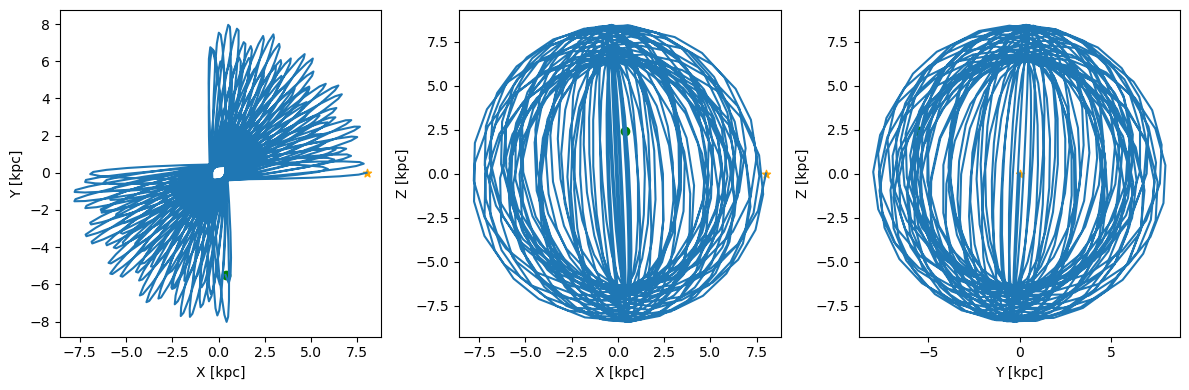

In [109]:
t=np.linspace(0,simulation_time,1000)
o=orb(t)
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1])
ax[0].scatter(final_pos[0],final_pos[1],c='orange',marker='*')
ax[0].scatter(mc_center[0],mc_center[1],c='green')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2])
ax[1].scatter(final_pos[0],final_pos[2],c='orange',marker='*')
ax[1].scatter(mc_center[0],mc_center[2],c='green')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2])
ax[2].scatter(final_pos[1],final_pos[2],c='orange',marker='*')
ax[2].scatter(mc_center[1],mc_center[2],c='green')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [110]:
def stellar_energy(N,M,R,v,its_sum):
    #b = np.sqrt(np.random.uniform(0, (1e-3)**2, N))
    b=np.random.uniform(10*R, (1e-4), N)
    E=((4*0.33*agama.G*agama.G*M*0.27*R*R)/((b**4)*(v**2)))
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:
        return E_sum
    else:
        return E_rms_sum

In [111]:
def N_encounter_new(t,xv, b_max=1e-3): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)

In [112]:
tupd = 1e-2
time_i = 0


mc_mass=mc.mass
mc_rvir=mc.radius
print('simulation time',simulation_time)


simulation time 10


In [113]:
#random stuff for plotting
mc_array=[mc_center]
mc_time=[]
pnum_array=[]
mass_array,radius_array=[],[]
Ef_array,Ei_array,E2_array,E3_array,N_encounter_with_star_array =[],[],[],[],[]
color=[0]
SD=[]
SD_r=[]
SD_t=[]
SD_axis=[]
R_vector=[]


In [114]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
from scipy.stats import uniform_direction

def generate_mc_particles(M_f,R_f, N,pmass,M_i,R_i,delE,r_t):    
    m_array=np.ones(N)*pmass
    pos_unit=uniform_direction(3).rvs(N)  # shape (N, 3)
    coords=r_t*pos_unit
    vel_unit = uniform_direction(3).rvs(N)  # shape (N, 3)
    
    E=(total_energy(binding_energy(M_f,R_f))-total_energy(binding_energy(M_i,R_i))+delE)/pnum
    v_ideal=np.sqrt(2*E)
    vel=v_ideal*vel_unit
    if len(vel)>0:print('v_fun=',v_ideal)
    return np.column_stack([coords, vel]), m_array


/tmp/ipykernel_2566783/3608404358.py:39: RuntimeWarning: divide by zero encountered in scalar divide
  E_pm=(total_energy(binding_energy(mc_mass,mc_rvir))-total_energy(binding_energy(mc_mass_old,mc_rvir_old))+delE)/pnum
/tmp/ipykernel_2566783/2799721158.py:12: RuntimeWarning: divide by zero encountered in scalar divide
  E=(total_energy(binding_energy(M_f,R_f))-total_energy(binding_energy(M_i,R_i))+delE)/pnum
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))
/tmp/ipykernel_2566783/360

dead
v_fun= 2.6160346243538735e-11


10000 orbits complete (230.8 orbits/s)                  


ValueError: 'c' argument has 10001 elements, which is inconsistent with 'x' and 'y' with size 10000.

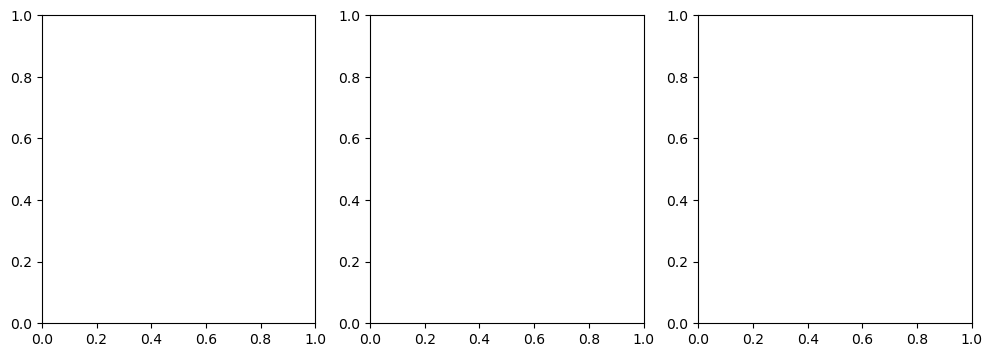

In [115]:
color_index=0
SD_count=0

while time_i < simulation_time-0.5*tupd:

    mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)
    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center)
    N_encounter_with_star_array.append(N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
    delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
    

    Eb=binding_energy(mc_mass,mc_rvir)
    Ei=total_energy(Eb)

    delEbyE=abs(delE/Eb)
    mass_loss=mc_mass*get_dm_frac(delEbyE)

    Ef=Ei+(1-get_fej(delEbyE))*delE-get_fub(delEbyE)*Ei
    
    Ef_array.append(Ef)
    Ei_array.append(Ei)
    E2_array.append((1-get_fej(delEbyE))*delE)
    E3_array.append(get_fub(delEbyE)*Ei)
    
    mc_mass_old=mc_mass
    mc_rvir_old=mc_rvir
    mc_mass=mc_mass-mass_loss
    mc_rvir=((kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef) if Ef<0 else 0

    mass_array.append(mc_mass)
    radius_array.append(mc_rvir)
    mc_array.append(mc_orbit_center)
    mc_time.append(mc_time_center[-1])

    r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass_old)
    pnum=round(mass_loss*Nbody_total/mc.mass)
    E_pm=(total_energy(binding_energy(mc_mass,mc_rvir))-total_energy(binding_energy(mc_mass_old,mc_rvir_old))+delE)/pnum
    
    pnum_array.append(pnum)
    if mc_rvir==0:
        print('dead')
        pnum=round(mc_mass_old*Nbody_total/mc.mass)
        mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass_old,mc_rvir_old,pnum,pmass,0,r_tidal,delE,r_tidal)
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        mcp_xv_temp+=mc_center
        mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
        mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=simulation_time-time_i, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=1)[:, 1])        
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)
        SD.append(pca.explained_variance_**0.5)
        alive=0
        break    
        
    if mcp_xv.size>0:
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
    
    mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,mc_rvir,pnum,pmass,mc_mass_old,mc_rvir_old,delE,r_tidal)
    mcp_xv_temp+=mc_orbit_center[-1]  
    mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
    mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
    
    if pnum>0 and color_index!=0:
        print(delE)
        print('v_p2',np.sqrt(2*E_pm))
        print('color_index:',color_index,'first')
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        color_index+=1
        print('time:',time_i,'pnum:',pnum,'mass:',mc_mass,'radius:',mc_rvir)
        fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
        ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.8,c=color,cmap='viridis')
        ax[0].scatter(mcp_xv_temp[:,0],mcp_xv_temp[:,1],s=2,c='orange') 
        ax[0].set_xlabel('X [kpc]')
        ax[0].set_ylabel('Y [kpc]')

        ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
        ax[1].scatter(mcp_xv_temp[:,0],mcp_xv_temp[:,2],s=2,c='orange')
        ax[1].set_xlabel('X [kpc]')
        ax[1].set_ylabel('Z [kpc]')

        ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
        ax[2].scatter(mcp_xv_temp[:,1],mcp_xv_temp[:,2],s=2,c='orange')
        ax[2].set_xlabel('Y [kpc]')
        ax[2].set_ylabel('Z [kpc]')
        plt.show()
        plt.tight_layout()
    elif pnum>0 and color_index==0:
        print(delE)
        print('color_index:',color_index,'second')
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)[1:]*color_index])
        color_index+=1
    """plt.plot(mcp_xv[:,0], mcp_xv[:,1], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,0], mcp_xv_temp[:,1], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][0], mc_orbit_center[-1][1], 's', markersize=5, color='red')
    plt.show()
    plt.plot(mcp_xv[:,0], mcp_xv[:,2], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,0], mcp_xv_temp[:,2], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][0], mc_orbit_center[-1][2], 's', markersize=5, color='red')
    plt.show()
    plt.plot(mcp_xv[:,1], mcp_xv[:,2], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,1], mcp_xv_temp[:,2], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][1], mc_orbit_center[-1][2], 's', markersize=5, color='red')
    plt.show()"""
        

    
    mc_center = mc_orbit_center[-1]

    time_i += tupd
    if mcp_xv.size>10 and SD_count%1==0 and time_i>0:
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)

        SD.append(pca.explained_variance_**0.5)
        SD_t.append(time_i)
    SD_count+=1
    #print(time_i,pnum)
#color=np.array(color[1:])
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.8,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')


plt.tight_layout()

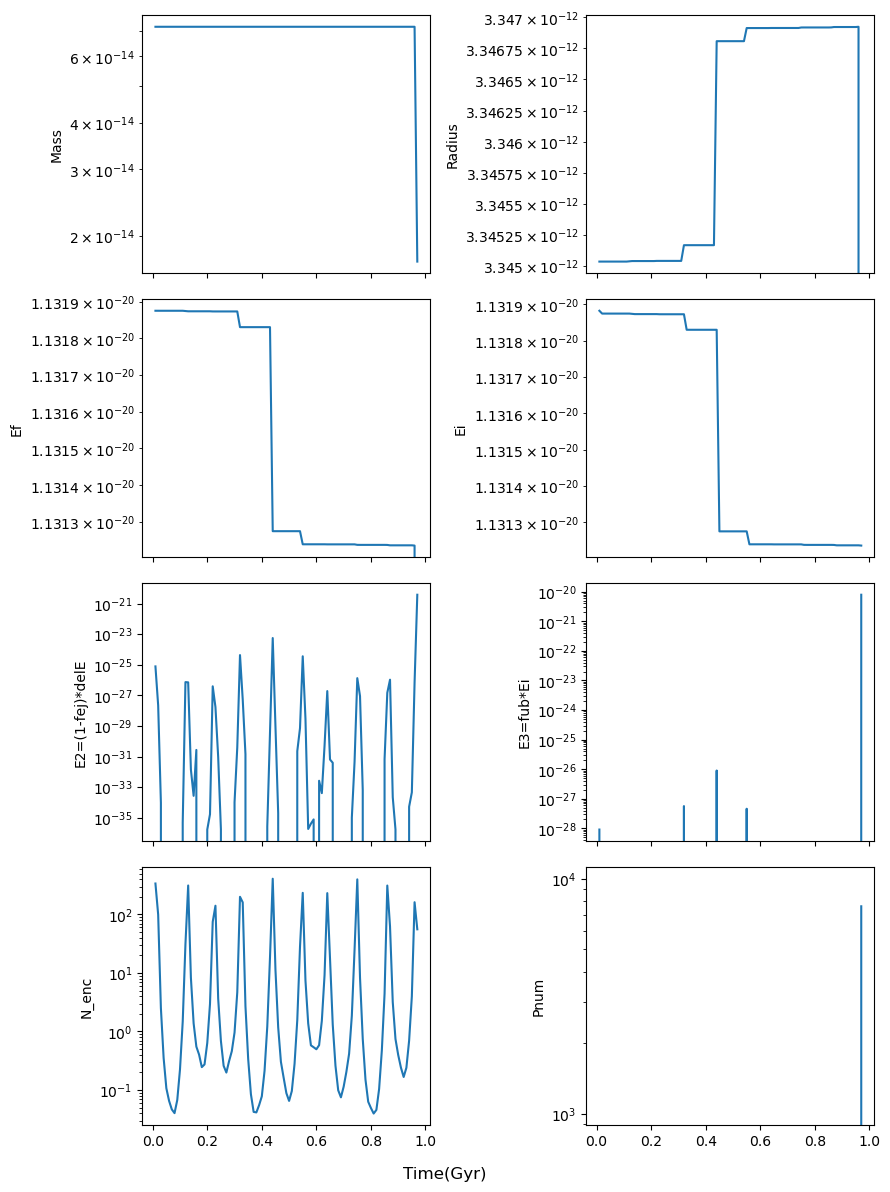

In [116]:
fig,ax=plt.subplots(4,2,figsize=(9,12),sharex=1)
ax[0,0].plot(mc_time,np.array(mass_array))
ax[0,0].set_ylabel('Mass')
ax[0,0].set_yscale('log')

ax[0,1].plot(mc_time,np.array(radius_array))
ax[0,1].set_ylabel('Radius')
ax[0,1].set_yscale('log')

ax[1,0].plot(mc_time,-np.array(Ef_array))
ax[1,0].set_ylabel('Ef')
ax[1,0].set_yscale('log')

ax[1,1].plot(mc_time,-np.array(Ei_array))
ax[1,1].set_ylabel('Ei')
ax[1,1].set_yscale('log')

ax[2,0].plot(mc_time,np.array(E2_array))
ax[2,0].set_ylabel('E2=(1-fej)*delE')
ax[2,0].set_yscale('log')

ax[2,1].plot(mc_time,-np.array(E3_array))
ax[2,1].set_ylabel('E3=fub*Ei')
ax[2,1].set_yscale('log')

ax[3,0].plot(mc_time,N_encounter_with_star_array)
ax[3,0].set_ylabel('N_enc')
ax[3,0].set_yscale('log')

ax[3,1].plot(mc_time,pnum_array)
ax[3,1].set_ylabel('Pnum')
ax[3,1].set_yscale('log')

fig.supxlabel('Time(Gyr)')

plt.tight_layout()

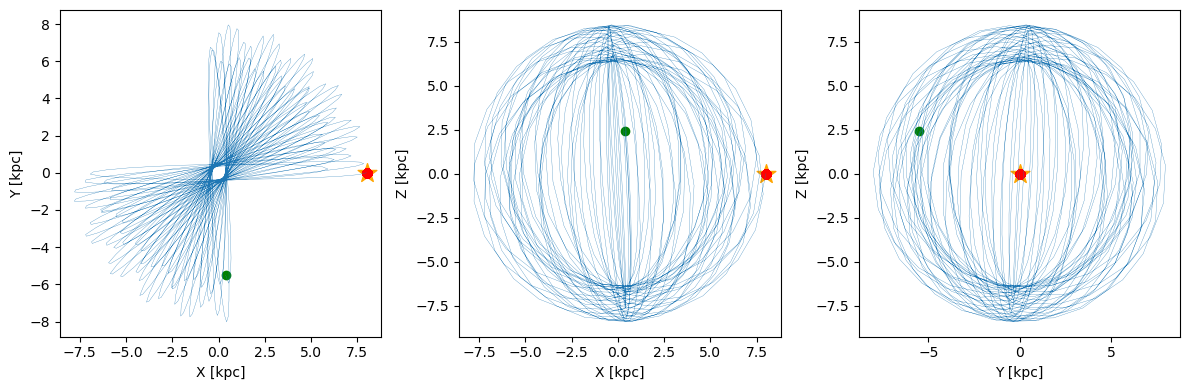

In [117]:
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1],lw=0.2)
ax[0].scatter(mc_end[0],mc_end[1],c='orange',marker='*',s=200)
ax[0].scatter(mc_start[0],mc_start[1],c='green')
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],c='r')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2],lw=0.2)
ax[1].scatter(mc_end[0],mc_end[2],c='orange',marker='*',s=200)
ax[1].scatter(mc_start[0],mc_start[2],c='green')
ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],c='r')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2],lw=0.2)
ax[2].scatter(mc_end[1],mc_end[2],c='orange',marker='*',s=200)
ax[2].scatter(mc_start[1],mc_start[2],c='green')
ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],c='r')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()
plt.show()


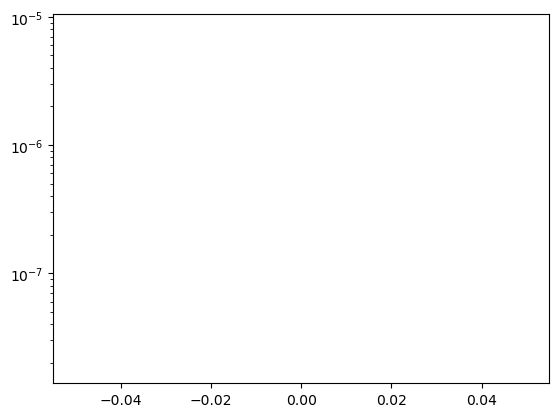

In [118]:
plt.plot(SD)
plt.yscale('log')
